# Dashboard · Thương mại hàng hóa Việt Nam 2005–2024
Dữ liệu: `trade_year.csv`, `section_year.csv`, `partner_year.csv` (CEPII BACI HS2002 V202601). Style: `house_style`.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter, MultipleLocator, MaxNLocator
from matplotlib.colors import to_rgb
from IPython.display import display

ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data/clean/trade_year.csv").is_file() and (p/"notebooks/house_style/house_style.py").is_file())
sys.path.insert(0,str(ROOT/"notebooks"))
from house_style.house_style import (apply_style, declutter, format_number, format_percent, format_percentage_points, format_year,
    TRADE_FLOW_COLORS, TRADE_FLOW_LABELS, TRADE_FLOW_LINESTYLES, TRADE_FLOW_MARKERS, TRADE_FLOW_ORDER,
    HS_COLORS, HS_LABELS, HS_ORDER, OTHER, COUNTRY_COLORS, DIVERGING_CMAP, DIRECT_LABEL, SUBTITLE, ANNOTATION, KPI, SOURCE,
    is_partner_code, grayscale)

D=ROOT/"data/clean"; OUT=ROOT/"outputs/dashboard"; T2=OUT/"tool2/data"; T2.mkdir(parents=True,exist_ok=True)
YEARS=tuple(range(2005,2025)); Y0,Y1=YEARS[0],YEARS[-1]; MILE=(2005,2010,2015,2020,2024); B=1e9
trade=pd.read_csv(D/"trade_year.csv",encoding="utf-8-sig")
sec=pd.read_csv(D/"section_year.csv",encoding="utf-8-sig",dtype={"section_code":str})
raw=pd.read_csv(D/"partner_year.csv",encoding="utf-8-sig",dtype={"partner_code":str,"partner_iso3":str})
NAMES={"USA":"Hoa Kỳ","CHN":"Trung Quốc","JPN":"Nhật Bản","KOR":"Hàn Quốc","HKG":"Hồng Kông","DEU":"Đức","SGP":"Singapore","THA":"Thái Lan"}
print(len(trade),len(sec),len(raw),"dòng")

20 840 6776 dòng


## 1. Xử lý dữ liệu

In [2]:
# --- C01A / KPI
t=trade[trade.year.between(Y0,Y1)].sort_values("year").set_index("year")
assert list(t.index)==list(YEARS) and np.allclose(t.export_usd-t.import_usd,t.trade_balance_usd,atol=.01)
t["export_bn"],t["import_bn"],t["balance_bn"],t["total_bn"]=(t[c]/B for c in ("export_usd","import_usd","trade_balance_usd","total_trade_usd"))
k,kp=t.loc[Y1],t.loc[Y1-1]
KPI_T=pd.DataFrame({"chi_so":["Xuất khẩu","Nhập khẩu","Cán cân","Tổng kim ngạch"],"nam":Y1,
  "ty_usd":[k.export_bn,k.import_bn,k.balance_bn,k.total_bn],
  "tang_truong_pct":[100*(k.export_usd/kp.export_usd-1),100*(k.import_usd/kp.import_usd-1),np.nan,100*(k.total_trade_usd/kp.total_trade_usd-1)]})

# --- C02A: Top 5 phần HS xuất khẩu theo tổng 5 năm mốc + Khác
s=sec[sec.trade_flow.eq("Export")&sec.year.isin(YEARS)]
codes=[c for c in HS_ORDER if c!=OTHER]
piv=s.pivot_table(index="year",columns="section_code",values="trade_usd",aggfunc="sum").reindex(columns=codes)
top5=sorted(codes,key=lambda c:-piv.loc[list(MILE),c].sum())[:5]; GROUPS=(*top5,OTHER)
g=piv[top5].copy(); g[OTHER]=piv.drop(columns=top5).sum(axis=1)
assert np.allclose(g.sum(axis=1),t.export_usd,rtol=1e-6), "tổng phần HS lệch trade_year"
SH=g.div(g.sum(axis=1),axis=0).loc[list(MILE)]            # tỷ trọng 0–1

# --- Đối tác hợp lệ (bỏ World/S19/999), tỷ trọng theo từng năm × chiều
valid=raw.partner_iso3.fillna("").map(is_partner_code)&~raw.partner_code.str.lstrip("0").isin(["","999"])
P=raw[valid&raw.year.between(Y0,Y1)&raw.trade_flow.isin(TRADE_FLOW_ORDER)].groupby(["year","trade_flow","partner_code"],as_index=False).agg(trade_usd=("trade_usd","sum"),partner_iso3=("partner_iso3","first"))
P["share"]=P.trade_usd/P.groupby(["year","trade_flow"]).trade_usd.transform("sum")
assert np.allclose(P.groupby(["year","trade_flow"]).share.sum(),1)

def c04(flow):
    r=P[P.year.isin([Y0,Y1])&P.trade_flow.eq(flow)]
    top=r.groupby("partner_code").trade_usd.sum().sort_index().nlargest(6).index
    w=r[r.partner_code.isin(top)].pivot(index="partner_code",columns="year",values="share").reindex(index=top,columns=[Y0,Y1]).fillna(0)
    iso=r[r.partner_code.isin(top)].sort_values("year").drop_duplicates("partner_code",keep="last").set_index("partner_code").partner_iso3.reindex(top)
    w.index=iso.map(NAMES).fillna(iso); w.index.name="doi_tac"; w["doi_pp"]=100*(w[Y1]-w[Y0]); return w
CX,CM=c04("Export"),c04("Import")

# --- C05A: HHI (0–10.000) trên đối tác hợp lệ
HHI=P.groupby(["year","trade_flow"]).share.agg(HHI=lambda s:10000*s.pow(2).sum()).HHI.unstack()[list(TRADE_FLOW_ORDER)]
print(KPI_T.round(1).to_string(index=False)); print(CX.round(3)); print(CM.round(3)); print(HHI.loc[[Y0,Y1]].round(0))

        chi_so  nam  ty_usd  tang_truong_pct
     Xuất khẩu 2024   505.2             15.5
     Nhập khẩu 2024   376.8             16.1
       Cán cân 2024   128.4              NaN
Tổng kim ngạch 2024   882.0             15.7
year         2005   2024  doi_pp
doi_tac                         
Hoa Kỳ      0.196  0.282   8.617
Trung Quốc  0.076  0.189  11.285
Nhật Bản    0.130  0.053  -7.692
Hàn Quốc    0.022  0.057   3.483
Hồng Kông   0.016  0.042   2.660
Đức         0.048  0.031  -1.744
year         2005   2024  doi_pp
doi_tac                         
Trung Quốc  0.171  0.438  26.693
Hàn Quốc    0.114  0.161   4.705
Singapore   0.127  0.047  -7.979
Hồng Kông   0.041  0.054   1.382
Nhật Bản    0.123  0.044  -7.892
Thái Lan    0.081  0.032  -4.897
trade_flow  Export  Import
year                      
2005         791.0   877.0
2024        1290.0  2298.0


## 2. Đối chiếu với `02_core_charts.ipynb`
Giá trị tham chiếu lấy từ phần kết luận/output của notebook gốc (C01A, C01B, C02A, C04A, C04B, C05A).

In [3]:
REF=pd.DataFrame([
 ("C01A XK 2024 (tỷ USD)",505.202,k.export_bn,.001),("C01A NK 2024 (tỷ USD)",376.826,k.import_bn,.001),
 ("C01B Cán cân 2024 (tỷ USD)",128.376,k.balance_bn,.001),
 ("C02A XVI 2005 (%)",9.4,100*SH.loc[2005,"XVI"],.05),("C02A XVI 2024 (%)",54.9,100*SH.loc[2024,"XVI"],.05),
 ("C02A Khác 2005 (%)",44.4,100*SH.loc[2005,OTHER],.05),("C02A Khác 2024 (%)",19.4,100*SH.loc[2024,OTHER],.05),
 ("C04A Trung Quốc thay đổi (pp)",11.3,CX.loc["Trung Quốc","doi_pp"],.05),("C04A Hoa Kỳ 2024 (%)",28.2,100*CX.loc["Hoa Kỳ",Y1],.05),
 ("C04B Trung Quốc thay đổi (pp)",26.7,CM.loc["Trung Quốc","doi_pp"],.05),("C04B Trung Quốc 2024 (%)",43.8,100*CM.loc["Trung Quốc",Y1],.05),
 ("C05A HHI XK 2005",791,HHI.loc[2005,"Export"],.5),("C05A HHI XK 2024",1290,HHI.loc[2024,"Export"],.5),
 ("C05A HHI NK 2005",877,HHI.loc[2005,"Import"],.5),("C05A HHI NK 2024",2298,HHI.loc[2024,"Import"],.5)],
 columns=["chi_tieu","goc","dashboard","dung_sai"])
REF["lech"]=REF.dashboard-REF.goc; REF["khop"]=REF.lech.abs()<=REF.dung_sai
assert tuple(GROUPS)==("XVI","XI","XII","XX","II",OTHER), GROUPS
assert set(CX.index)=={"Hoa Kỳ","Trung Quốc","Nhật Bản","Hàn Quốc","Hồng Kông","Đức"} and set(CM.index)=={"Trung Quốc","Hàn Quốc","Singapore","Hồng Kông","Nhật Bản","Thái Lan"}
display(REF.round(3)); assert REF.khop.all(), "Có chỉ tiêu lệch notebook gốc"; print("Khớp", int(REF.khop.sum()),"/",len(REF),"chỉ tiêu; nhóm HS và đối tác trùng notebook gốc.")

,chi_tieu,goc,dashboard,dung_sai,lech,khop
0,C01A XK 2024 (tỷ USD),505.202,505.202,0.001,-0.000,True
1,C01A NK 2024 (tỷ USD),376.826,376.826,0.001,-0.000,True
2,C01B Cán cân 2024 (tỷ USD),128.376,128.376,0.001,0.000,True
3,C02A XVI 2005 (%),9.400,9.407,0.050,0.007,True
4,C02A XVI 2024 (%),54.900,54.901,0.050,0.001,True
5,C02A Khác 2005 (%),44.400,44.403,0.050,0.003,True
6,C02A Khác 2024 (%),19.400,19.392,0.050,-0.008,True
7,C04A Trung Quốc thay đổi (pp),11.300,11.285,0.050,-0.015,True
8,C04A Hoa Kỳ 2024 (%),28.200,28.249,0.050,0.049,True
9,C04B Trung Quốc thay đổi (pp),26.700,26.693,0.050,-0.007,True


Khớp 15 / 15 chỉ tiêu; nhóm HS và đối tác trùng notebook gốc.


## 3. Dashboard (`subplot_mosaic`)

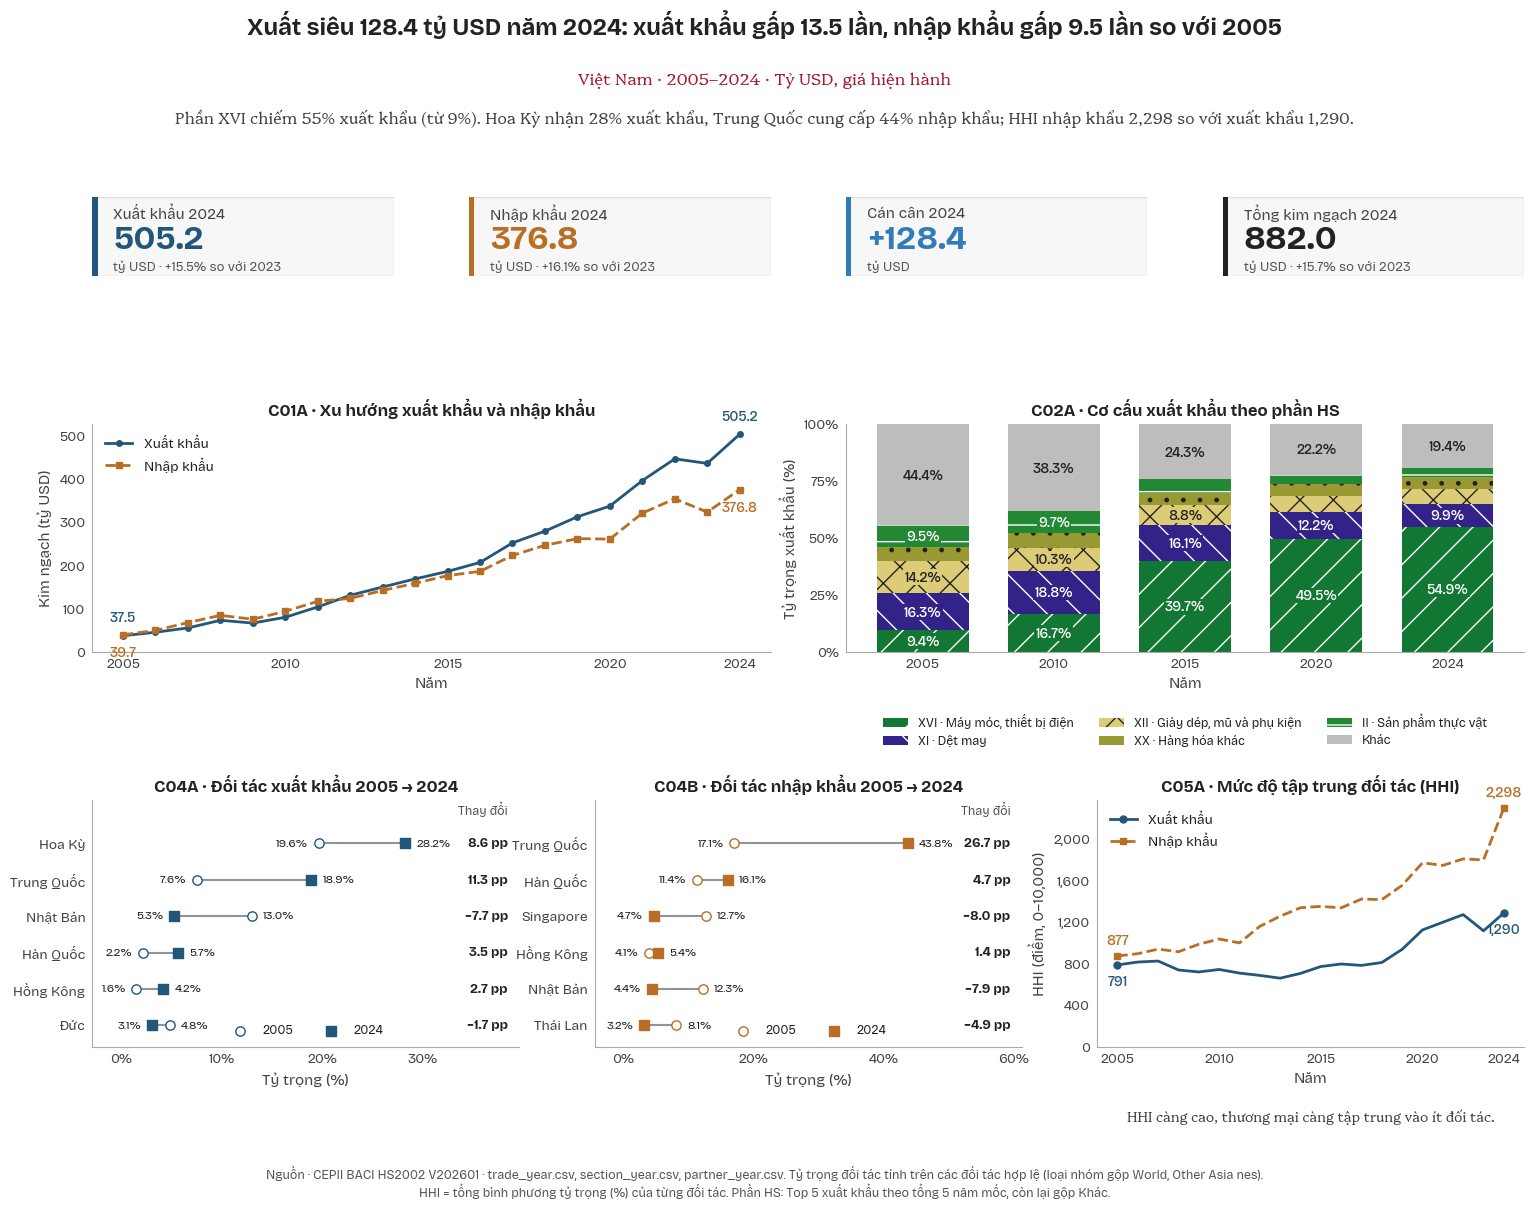

In [4]:
def pname(c): return HS_LABELS[c]
def ink_for(color): return "#FFFFFF" if float(grayscale(to_rgb(color))[0])<.55 else "#222222"
HATCH=("/",chr(92),"x",".","-","")
VN=COUNTRY_COLORS["VNM"]
bal_col=DIVERGING_CMAP(.85 if k.balance_bn>=0 else .15)

# Câu kết luận tính từ dữ liệu
lead_x,lead_m=CX[Y1].idxmax(),CM[Y1].idxmax(); lead_g=GROUPS[0]
ratio_x,ratio_m=t.export_usd.iloc[-1]/t.export_usd.iloc[0],t.import_usd.iloc[-1]/t.import_usd.iloc[0]
TITLE=f"Xuất siêu {format_number(k.balance_bn,1)} tỷ USD năm {Y1}: xuất khẩu gấp {format_number(ratio_x,1)} lần, nhập khẩu gấp {format_number(ratio_m,1)} lần so với {Y0}"
KEY=(f"Phần {lead_g} chiếm {format_percent(SH.loc[Y1,lead_g],0)} xuất khẩu (từ {format_percent(SH.loc[Y0,lead_g],0)}). "
     f"{lead_x} nhận {format_percent(CX.loc[lead_x,Y1],0)} xuất khẩu, {lead_m} cung cấp {format_percent(CM.loc[lead_m,Y1],0)} nhập khẩu; "
     f"HHI nhập khẩu {format_number(HHI.loc[Y1,'Import'])} so với xuất khẩu {format_number(HHI.loc[Y1,'Export'])}.")

with apply_style():
    LAYOUT=[["k1"]*3+["k2"]*3+["k3"]*3+["k4"]*3,["A"]*6+["B"]*6,["C"]*4+["D"]*4+["E"]*4]
    fig,ax=plt.subplot_mosaic(LAYOUT,figsize=(16,12.5),height_ratios=[.8,2.3,2.5],
        gridspec_kw=dict(left=.08,right=.975,top=.83,bottom=.15,hspace=.8,wspace=1.5))
    fig.suptitle(TITLE,y=.98,fontsize=17)
    fig.text(.5,.93,f"Việt Nam · {Y0}–{Y1} · Tỷ USD, giá hiện hành",va="top",**{**SUBTITLE,"color":VN})
    fig.text(.5,.90,KEY,va="top",fontsize=11.5,**ANNOTATION,color="#444444")

    # Hàng số liệu
    cards=[("k1",f"Xuất khẩu {Y1}",k.export_bn,TRADE_FLOW_COLORS["Export"],False,KPI_T.tang_truong_pct[0]),
           ("k2",f"Nhập khẩu {Y1}",k.import_bn,TRADE_FLOW_COLORS["Import"],False,KPI_T.tang_truong_pct[1]),
           ("k3",f"Cán cân {Y1}",k.balance_bn,bal_col,True,np.nan),
           ("k4",f"Tổng kim ngạch {Y1}",k.total_bn,"#222222",False,KPI_T.tang_truong_pct[3])]
    for key,lab,val,col,signed,gr in cards:
        a=ax[key]; a.set_axis_off()
        a.add_patch(Rectangle((0,0),1,1,transform=a.transAxes,fc="#F7F7F7",ec="#DDDDDD"))
        a.add_patch(Rectangle((0,0),.018,1,transform=a.transAxes,fc=col,ec="none"))
        a.text(.07,.80,lab,transform=a.transAxes,fontsize=11,color="#444444",va="center",fontfamily=KPI["fontfamily"])
        a.text(.07,.46,format_number(val,1,signed=signed),transform=a.transAxes,fontsize=24,color=col,va="center",**KPI)
        sub="tỷ USD"+("" if np.isnan(gr) else f" · {'+' if gr>=0 else '−'}{abs(gr):.1f}% so với {Y1-1}")
        a.text(.07,.13,sub,transform=a.transAxes,fontsize=9.5,color="#555555",va="center",fontfamily=KPI["fontfamily"])

    # A · C01A
    a=ax["A"]
    for fl,col in (("Export","export_bn"),("Import","import_bn")):
        a.plot(t.index,t[col],color=TRADE_FLOW_COLORS[fl],linestyle=TRADE_FLOW_LINESTYLES[fl],marker=TRADE_FLOW_MARKERS[fl],markersize=4,label=TRADE_FLOW_LABELS[fl])
        for y in (Y0,Y1):
            a.annotate(format_number(t.loc[y,col],1),(y,t.loc[y,col]),xytext=(0,10 if fl=="Export" else -16),textcoords="offset points",ha="center",color=TRADE_FLOW_COLORS[fl],**DIRECT_LABEL)
    a.set(ylim=(0,None),xlabel="Năm",ylabel="Kim ngạch (tỷ USD)"); a.set_xticks([Y0,2010,2015,2020,Y1]); declutter(a)
    a.set_title("C01A · Xu hướng xuất khẩu và nhập khẩu",fontsize=12); a.legend(loc="upper left")

    # B · C02A
    a=ax["B"]; pos=np.arange(len(MILE)); bot=np.zeros(len(MILE))
    for grp,h in zip(GROUPS,HATCH):
        col=HS_COLORS[grp]; ink=ink_for(col); v=SH[grp].values
        a.bar(pos,v,bottom=bot,width=.7,color=col,edgecolor=ink,linewidth=0,hatch=h,label=pname(grp))
        for x,b0,s_ in zip(pos,bot,v):
            if s_>=.085: a.text(x,b0+s_/2,format_percent(s_),ha="center",va="center",color=ink,bbox={"facecolor":col,"edgecolor":"none","pad":1},**DIRECT_LABEL)
        bot+=v
    a.set(ylim=(0,1),xlabel="Năm",ylabel="Tỷ trọng xuất khẩu (%)"); a.set_xticks(pos,[format_year(y) for y in MILE])
    a.yaxis.set_major_locator(MultipleLocator(.25)); a.yaxis.set_major_formatter(FuncFormatter(lambda v,_:format_percent(v,0)))
    a.set_title("C02A · Cơ cấu xuất khẩu theo phần HS",fontsize=12); a.legend(ncols=3,loc="upper center",bbox_to_anchor=(.5,-.22),fontsize=9)

    # C, D · C04A/B
    def dumb(a,d,flow,title):
        col=TRADE_FLOW_COLORS[flow]; y=np.arange(len(d))
        a.hlines(y,100*d[[Y0,Y1]].min(axis=1),100*d[[Y0,Y1]].max(axis=1),color="#8D959B",linewidth=1.5)
        for yr,mk,fill in ((Y0,"o","white"),(Y1,"s",col)):
            a.scatter(d[yr]*100,y,marker=mk,edgecolors=col,facecolors=fill,label=str(yr),zorder=3,s=45)
            for yi,v in zip(y,d[yr]):
                left=v<=d.loc[d.index[yi],[Y0,Y1]].max() and v==d.loc[d.index[yi],[Y0,Y1]].min()
                a.annotate(format_percent(v,1),(v*100,yi),xytext=(-8 if left else 8,0),textcoords="offset points",ha="right" if left else "left",va="center",fontsize=8.5)
        xmax=100*max(d[Y0].max(),d[Y1].max())
        for yi,dp in zip(y,d.doi_pp): a.text(xmax*1.36,yi,format_percentage_points(dp),ha="right",va="center",color="#222222",fontweight="bold",fontsize=9.5)
        a.text(xmax*1.36,-.95,"Thay đổi",ha="right",va="center",fontsize=9,color="#555555")
        a.set(yticks=y,yticklabels=d.index,ylim=(len(d)-.4,-1.2),xlim=(-xmax*.1,xmax*1.4),xlabel="Tỷ trọng (%)")
        a.xaxis.set_major_locator(MaxNLocator(5,steps=[1,2,5,10])); a.xaxis.set_major_formatter(FuncFormatter(lambda v,_:format_number(v,0)+"%"))
        for sd in ("top","right"): a.spines[sd].set_visible(False)
        a.set_title(title,fontsize=12); a.legend(ncols=2,loc="lower center",fontsize=9)
    dumb(ax["C"],CX,"Export",f"C04A · Đối tác xuất khẩu {Y0} → {Y1}"); dumb(ax["D"],CM,"Import",f"C04B · Đối tác nhập khẩu {Y0} → {Y1}")

    # E · C05A
    a=ax["E"]
    for fl in TRADE_FLOW_ORDER:
        v=HHI[fl]; a.plot(v.index,v.values,color=TRADE_FLOW_COLORS[fl],linestyle=TRADE_FLOW_LINESTYLES[fl],marker=TRADE_FLOW_MARKERS[fl],markevery=[0,len(v)-1],label=TRADE_FLOW_LABELS[fl])
        for y_ in (Y0,Y1): a.annotate(format_number(v.loc[y_]),(y_,v.loc[y_]),xytext=(0,8 if fl=="Import" else -15),textcoords="offset points",ha="center",color=TRADE_FLOW_COLORS[fl],**DIRECT_LABEL)
    a.set(xlim=(Y0-1,Y1+1),ylim=(0,None),xlabel="Năm",ylabel="HHI (điểm, 0–10,000)"); a.set_xticks([Y0,2010,2015,2020,Y1])
    a.yaxis.set_major_formatter(FuncFormatter(lambda v,_:format_number(v))); declutter(a)
    a.set_title("C05A · Mức độ tập trung đối tác (HHI)",fontsize=12); a.legend(loc="upper left")
    a.text(.5,-.30,"HHI càng cao, thương mại càng tập trung vào ít đối tác.",transform=a.transAxes,fontsize=10,**ANNOTATION,color="#444444")

    fig.text(.5,.055,"Nguồn · CEPII BACI HS2002 V202601 · trade_year.csv, section_year.csv, partner_year.csv. Tỷ trọng đối tác tính trên các đối tác hợp lệ (loại nhóm gộp World, Other Asia nes).\nHHI = tổng bình phương tỷ trọng (%) của từng đối tác. Phần HS: Top 5 xuất khẩu theo tổng 5 năm mốc, còn lại gộp Khác.",va="top",**SOURCE)
    fig.savefig(OUT/"dashboard_v1.png",dpi=300); fig.savefig(OUT/"dashboard_v1.pdf")
plt.show()

## 4. Bảng cho công cụ thứ hai

In [5]:
def save(df,name): df.to_csv(T2/name,index=False,encoding="utf-8-sig")
def pw(d): return d.reset_index().rename(columns={Y0:"share_2005",Y1:"share_2024"}).assign(share_2005=lambda x:x.share_2005*100,share_2024=lambda x:x.share_2024*100)
save(KPI_T,"kpi_2024.csv")
save(t.reset_index()[["year","export_bn","import_bn","balance_bn","total_bn"]],"c01a_trend.csv")
sh=SH.mul(100).rename_axis("year").reset_index().melt("year",var_name="section_code",value_name="share_pct")
sh["section_label"]=sh.section_code.map(pname); sh["export_bn"]=[g.loc[y,c]/B for y,c in zip(sh.year,sh.section_code)]
save(sh,"c02a_section_share.csv"); save(pw(CX),"c04a_partner_export.csv"); save(pw(CM),"c04b_partner_import.csv")
save(HHI.rename(columns=TRADE_FLOW_LABELS).rename_axis("year").reset_index(),"c05a_hhi.csv"); save(REF,"doi_chieu_02_core_charts.csv")
print(sorted(p.name for p in T2.glob("*.csv")))

['c01a_trend.csv', 'c02a_section_share.csv', 'c04a_partner_export.csv', 'c04b_partner_import.csv', 'c05a_hhi.csv', 'doi_chieu_02_core_charts.csv', 'kpi_2024.csv']
